# 02 — Preprocesamiento de datos

## Dataset: allpaDB (capas de suelo armonizadas)

**Objetivo del proyecto:** predecir el **Carbono Orgánico del Suelo (`ORGC`, en %)** a partir de propiedades físico-químicas de cada capa de suelo → es un problema de **regresión**.

**Objetivo de este notebook:** dejar los datos listos para la etapa de evaluación de modelos. Aquí **no** se entrena ningún modelo; solo se limpia, transforma y guarda la data.

Cada decisión se toma a partir de lo encontrado en el notebook `01_EDA`:

| Hallazgo del EDA | Decisión en este notebook |
|---|---|
| `ORGC` (target) tiene 11.2 % de faltantes y un máximo de 249 % | Eliminar filas sin target y valores > 100 % (imposibles) |
| `SAND + SILT + CLAY` no siempre suma 100 (mín. 20, máx. 500) | Marcar esas texturas como faltantes (NaN) para imputarlas |
| `PHAQ` tiene un mínimo de 0.08 (pH irreal para un suelo) | Marcar pH < 2 como faltante |
| `upper_depth` y `lower_depth` muy correlacionadas (r = 0.81) | Reemplazarlas por `depth_mid` (profundidad media) y `thickness` (espesor) |
| `SAND` es combinación lineal de `SILT` y `CLAY` | Eliminar `SAND` |
| Faltantes: `ELCOSP` 38 %, `ECEC` 29 %, textura ~14 %, `TCEQ` 13 % | Imputar con media o mediana según la asimetría de cada feature |
| `TCEQ`, `ELCOSP`, `ECEC` muy asimétricas y con muchos outliers | Transformación logarítmica + recorte (clipping) por IQR |
| Escalas muy distintas entre features | `StandardScaler` (versión escalada) y versión sin escalar |

## 1. Inicializar

In [1]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Preprocesamiento
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilos
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 5)

## 2. Importar dataset

Se seleccionan las mismas variables definidas en el EDA. Además se conserva `profile_code` (código del perfil de suelo) **solo** para hacer la división train/test por perfil (ver sección 6); no se usa como feature.

In [2]:
df_raw = pd.read_csv('../data/raw/allpaDB_layer_HARMONIZED_v1.csv')

print(f"Dimensiones iniciales del dataset: {df_raw.shape[0]} filas, {df_raw.shape[1]} columnas")

Dimensiones iniciales del dataset: 24341 filas, 45 columnas


In [3]:
target = 'ORGC'  # Carbono Orgánico en Suelo (%)
features = ['upper_depth', 'lower_depth', 'PHAQ', 'SAND', 'SILT', 'CLAY', 'TCEQ', 'ELCOSP', 'ECEC']

df_model = df_raw[['profile_code'] + features + [target]].copy()

print(df_model.shape)
df_model.head()

(24341, 11)


,profile_code,upper_depth,lower_depth,PHAQ,SAND,SILT,CLAY,TCEQ,ELCOSP,ECEC,ORGC
0,Angostura,0.0,10.0,8.2,90.0,8.0,2.0,0.85,1.032625,2.24,0.12
1,Angostura,10.0,40.0,8.5,96.0,4.0,0.0,1.05,0.768510,1.36,0.12
2,Angostura,40.0,55.0,8.5,94.0,6.0,0.0,0.66,1.351237,2.00,0.12
3,Angostura,55.0,90.0,8.4,96.0,4.0,0.0,0.76,1.644262,1.84,0.08
4,Angostura,90.0,200.0,8.0,40.0,54.0,6.0,0.19,3.087263,7.76,0.52


## 3. Variable objetivo (`ORGC`)

#### 3.1 Filas sin valor de `ORGC`

**¿Por qué eliminarlas y no imputarlas?** El target es lo que el modelo debe aprender a predecir. Si se imputa (por ejemplo con la mediana) se le estaría enseñando al modelo una "respuesta inventada", lo que sesga el entrenamiento y la evaluación. Por eso las filas sin `ORGC` se eliminan.

In [4]:
missing_target = df_model[target].isnull().sum()
print(f"Filas sin ORGC: {missing_target} ({missing_target / len(df_model) * 100:.2f} %)")

df_model = df_model[df_model[target].notnull()].copy()
print(f"Filas restantes: {len(df_model)}")

Filas sin ORGC: 2732 (11.22 %)
Filas restantes: 21609


#### 3.2 Valores imposibles de `ORGC`

`ORGC` está expresado en **porcentaje**, por lo que un valor mayor a 100 % es físicamente imposible (en el EDA se observó un máximo de 249 %). Son errores de registro o de unidades, así que esas filas se eliminan. Los valores altos pero posibles (suelos orgánicos / turberas) **sí se conservan**.

In [5]:
invalid_target = (df_model[target] > 100).sum()
print(f"Filas con ORGC > 100 %: {invalid_target}")

df_model = df_model[df_model[target] <= 100].copy()
print(f"Filas restantes: {len(df_model)}")

Filas con ORGC > 100 %: 8
Filas restantes: 21601


## 4. Consistencia de los datos

En vez de eliminar filas completas por un solo valor erróneo, los valores **físicamente imposibles** se convierten en `NaN`. Así se conserva la información válida del resto de columnas de esa fila y el valor erróneo se trata luego en la imputación.

#### 4.1 Textura del suelo (`SAND`, `SILT`, `CLAY`)

Las tres fracciones de textura son porcentajes de un mismo total, por lo que deberían sumar 100. En el EDA la suma iba de 20 a 500. Se acepta una tolerancia de ±5 por redondeos de laboratorio; fuera de ese rango, la textura de esa capa no es confiable y se marca como faltante.

In [6]:
texture_cols = ['SAND', 'SILT', 'CLAY']

texture_sum = df_model[texture_cols].sum(axis=1, min_count=3)
texture_invalid = (texture_sum - 100).abs() > 5

print(f"Capas con textura completa: {texture_sum.notnull().sum()}")
print(f"Capas con suma fuera de 100 ± 5: {texture_invalid.sum()}")

df_model.loc[texture_invalid, texture_cols] = np.nan

# Verificación: ninguna fracción mayor a 100
print(f"Valores > 100 en textura después de la corrección: {(df_model[texture_cols] > 100).sum().sum()}")

Capas con textura completa: 19712
Capas con suma fuera de 100 ± 5: 134
Valores > 100 en textura después de la corrección: 0


#### 4.2 pH (`PHAQ`)

El pH de suelos reales se encuentra aproximadamente entre 3 y 11. Un pH menor a 2 (el EDA mostró un mínimo de 0.08) es un error de medición o de digitación, por lo que se marca como faltante.

In [7]:
ph_invalid = df_model['PHAQ'] < 2
print(f"Valores de PHAQ < 2: {ph_invalid.sum()}")

df_model.loc[ph_invalid, 'PHAQ'] = np.nan

Valores de PHAQ < 2: 32


#### 4.3 Profundidades

En el EDA se verificó que no existen capas con `lower_depth <= upper_depth`. Se vuelve a confirmar sobre los datos actuales; si fuera 0, no se requiere ninguna acción.

In [8]:
depth_check = df_model[['upper_depth', 'lower_depth']].dropna()
print(f"Capas con profundidad inconsistente: {(depth_check['lower_depth'] - depth_check['upper_depth'] <= 0).sum()}")

Capas con profundidad inconsistente: 0


## 5. Features correlacionadas

Features muy correlacionadas entre sí aportan información repetida y generan **multicolinealidad**, que vuelve inestables a los modelos lineales (coeficientes que cambian mucho con pequeñas variaciones de los datos) y dificulta interpretar la importancia de cada variable.

#### 5.1 `upper_depth` y `lower_depth`

En el EDA ambas tenían una correlación de 0.81: describen prácticamente lo mismo (a qué profundidad está la capa). En lugar de eliminar una de ellas, se reemplazan por dos variables con significado edafológico más claro:

- `depth_mid` = (upper_depth + lower_depth) / 2 → **a qué profundidad** está la capa.
- `thickness` = lower_depth − upper_depth → **qué tan gruesa** es la capa.

In [9]:
df_model['depth_mid'] = (df_model['upper_depth'] + df_model['lower_depth']) / 2
df_model['thickness'] = df_model['lower_depth'] - df_model['upper_depth']

depth_corr = df_model[['upper_depth', 'lower_depth', 'depth_mid', 'thickness']].corr().round(2)
depth_corr

,upper_depth,lower_depth,depth_mid,thickness
upper_depth,1.00,0.81,0.93,0.27
lower_depth,0.81,1.00,0.97,0.78
depth_mid,0.93,0.97,1.00,0.61
thickness,0.27,0.78,0.61,1.00


La correlación entre las dos nuevas variables (≈ 0.61) es menor que la de las originales (0.81), por lo que la redundancia baja sin perder la información de profundidad. Se eliminan `upper_depth` y `lower_depth`.

In [10]:
df_model = df_model.drop(columns=['upper_depth', 'lower_depth'])

#### 5.2 `SAND`, `SILT` y `CLAY`

Al ser fracciones de un mismo 100 %, se cumple que `SAND ≈ 100 − SILT − CLAY`: una de las tres es **redundante por definición** (colinealidad perfecta). Se elimina `SAND` porque es la más correlacionada con las otras dos; su información queda contenida en `SILT` y `CLAY`.

In [11]:
df_model[texture_cols].corr().round(2)

,SAND,SILT,CLAY
SAND,1.00,-0.72,-0.80
SILT,-0.72,1.00,0.16
CLAY,-0.80,0.16,1.00


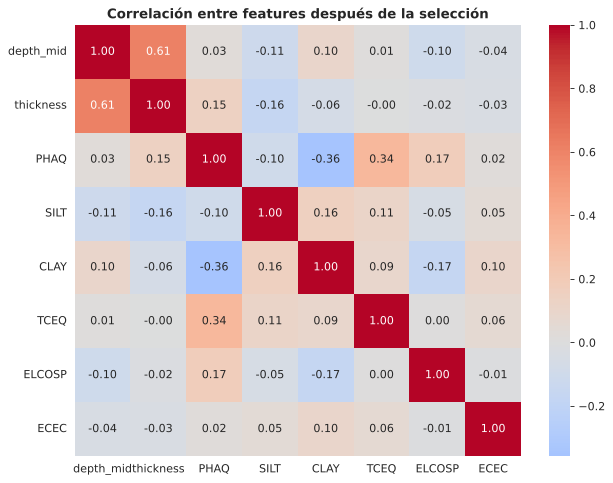

In [12]:
df_model = df_model.drop(columns=['SAND'])

features_final = ['depth_mid', 'thickness', 'PHAQ', 'SILT', 'CLAY', 'TCEQ', 'ELCOSP', 'ECEC']

corr_features = df_model[features_final].corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_features, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlación entre features después de la selección', fontweight='bold')
plt.show()

## 6. División train / test

**¿Por qué dividir antes de imputar, transformar y escalar?** Todos los pasos siguientes "aprenden" algo de los datos (la mediana para imputar, los límites del IQR, la media y desviación del escalador). Si se calculan con todo el dataset, información del conjunto de prueba se filtra al entrenamiento (**data leakage**) y las métricas salen optimistas. Por eso, desde aquí, todo se **ajusta (`fit`) solo con train** y luego se **aplica (`transform`) a train y test**.

**¿Por qué dividir por perfil y no por fila?** Cada perfil de suelo (`profile_code`) tiene varias capas muy parecidas entre sí. Si las capas de un mismo perfil quedaran repartidas entre train y test, el modelo vería en entrenamiento "vecinos casi idénticos" de las filas de prueba. Para evitarlo, se usa `train_test_split` sobre la **lista de perfiles** (80 % / 20 %), y cada perfil queda completo en un solo conjunto.

In [13]:
profiles = df_model['profile_code'].unique()

train_profiles, test_profiles = train_test_split(profiles, test_size=0.2, random_state=42)

train_df = df_model[df_model['profile_code'].isin(train_profiles)].copy()
test_df = df_model[df_model['profile_code'].isin(test_profiles)].copy()

split_df = pd.DataFrame({
    'Conjunto': ['Train', 'Test'],
    'Perfiles': [len(train_profiles), len(test_profiles)],
    'Capas (filas)': [len(train_df), len(test_df)],
    'Porcentaje (%)': [round(len(train_df) / len(df_model) * 100, 1), round(len(test_df) / len(df_model) * 100, 1)]
})

print(f"Perfiles compartidos entre train y test: {len(set(train_profiles) & set(test_profiles))}")
split_df

Perfiles compartidos entre train y test: 0


,Conjunto,Perfiles,Capas (filas),Porcentaje (%)
0,Train,6564,17338,80.3
1,Test,1642,4263,19.7


In [14]:
# Separar características y target (profile_code ya no se necesita)
X_train = train_df[features_final].copy()
y_train = train_df[target].copy()

X_test = test_df[features_final].copy()
y_test = test_df[target].copy()

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

X_train: (17338, 8) | X_test: (4263, 8)


## 7. Transformación logarítmica (features asimétricas)

`TCEQ`, `ELCOSP`, `ECEC` y `thickness` tienen asimetrías muy altas (colas largas a la derecha). Con distribuciones así:

- el método IQR marcaría como outliers a una gran parte de los datos, aunque sean valores reales;
- los modelos lineales y basados en distancias quedan dominados por los pocos valores extremos.

Se aplica **`log1p` = log(1 + x)**, que comprime la cola derecha. Se usa `log1p` (y no `log`) porque estas variables tienen **ceros** (por ejemplo, `TCEQ` es 0 en más de la mitad de las capas no calcáreas) y log(0) no está definido. Es una transformación fija (no aprende parámetros de los datos), así que no genera leakage.

In [15]:
log_cols = ['TCEQ', 'ELCOSP', 'ECEC', 'thickness']

skew_before = X_train[log_cols].skew()

X_train[log_cols] = np.log1p(X_train[log_cols])
X_test[log_cols] = np.log1p(X_test[log_cols])

skew_after = X_train[log_cols].skew()

log_df = pd.DataFrame({
    'Columna': log_cols,
    'Asimetría antes': skew_before.values.round(2),
    'Asimetría después (log1p)': skew_after.values.round(2)
})

log_df

,Columna,Asimetría antes,Asimetría después (log1p)
0,TCEQ,5.85,1.85
1,ELCOSP,6.66,1.36
2,ECEC,33.20,-0.53
3,thickness,2.52,0.47


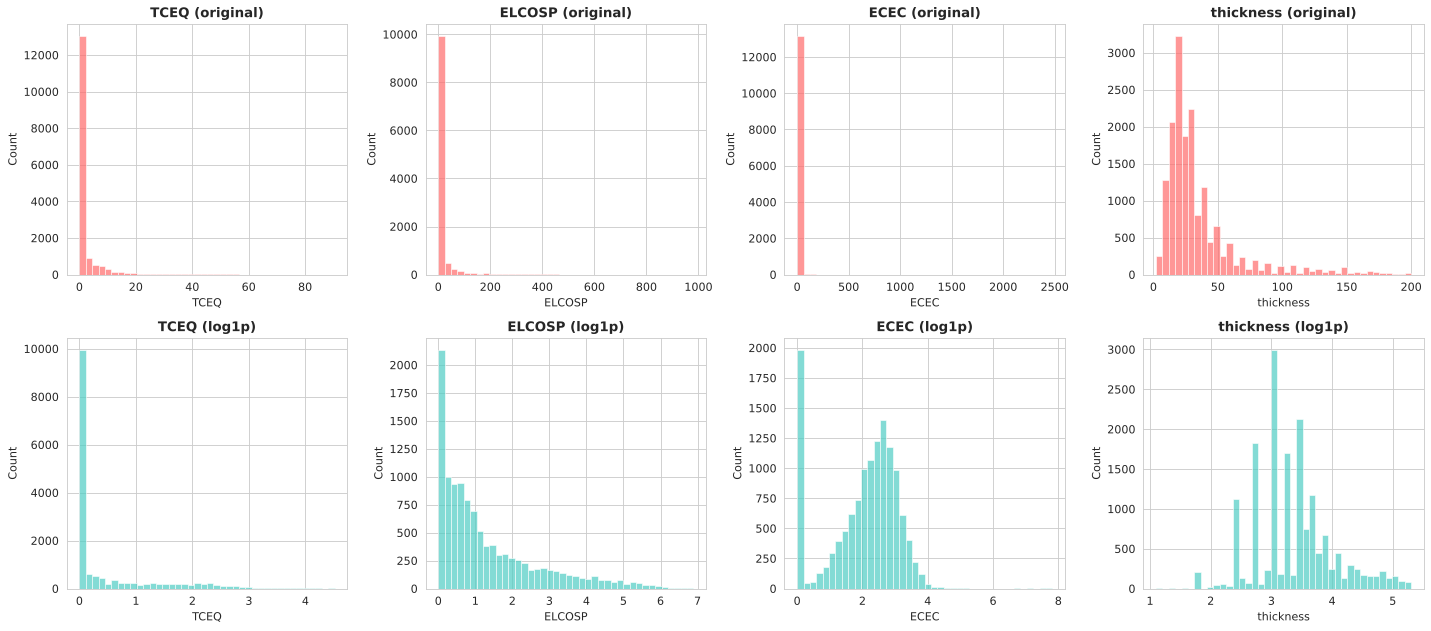

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for i, col in enumerate(log_cols):
    sns.histplot(np.expm1(X_train[col]), ax=axes[0, i], bins=40, color='#FF6B6B', alpha=0.7)
    axes[0, i].set_title(f'{col} (original)', fontweight='bold')

    sns.histplot(X_train[col], ax=axes[1, i], bins=40, color='#4ECDC4', alpha=0.7)
    axes[1, i].set_title(f'{col} (log1p)', fontweight='bold')

plt.tight_layout()
plt.show()

## 8. Detección y tratamiento de outliers

#### 8.1 Detección con IQR (sobre train)

Se usa IQR (y no Z-score) porque varias features siguen sin ser normales, y el Z-score asume normalidad.

**¿Por qué antes de imputar?** Los cuartiles se calculan solo con los **valores reales** (pandas ignora los `NaN`). Si se imputara primero, ~35 % de `ELCOSP` y ~24 % de `ECEC` tendrían el mismo valor (la mediana), el IQR se encogería artificialmente y se marcarían como outliers valores normales.

In [17]:
Q1 = X_train.quantile(0.25)
Q3 = X_train.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Outliers por columna (booleano)
outliers_iqr = (X_train < lower_bound) | (X_train > upper_bound)

# Resumen
outliers_summary = pd.DataFrame({
    'Columna': outliers_iqr.columns,
    'Q1': Q1.values.round(3),
    'Q3': Q3.values.round(3),
    'Outliers': outliers_iqr.sum().values,
    'Porcentaje (%)': (outliers_iqr.sum().values / len(X_train) * 100).round(2)
})

outliers_summary.sort_values('Outliers', ascending=False)

,Columna,Q1,Q3,Outliers,Porcentaje (%)
5,TCEQ,0.000,0.631,2205,12.72
1,thickness,3.045,3.714,962,5.55
6,ELCOSP,0.285,1.896,541,3.12
3,SILT,18.000,36.000,224,1.29
4,CLAY,8.000,32.000,138,0.80
0,depth_mid,12.500,72.500,78,0.45
7,ECEC,1.454,2.785,20,0.12
2,PHAQ,5.100,7.900,0,0.00


In [18]:
def plot_boxplots(df, features, title='Boxplots'):
    # Visualiza boxplots de características para detectar outliers
    fig, axes = plt.subplots(2, 4, figsize=(16, 8))
    axes = axes.flatten()

    for i, col in enumerate(features):
        axes[i].boxplot(df[col].dropna())

        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        outlier_count = ((df[col] < Q1 - 1.5*IQR) | (df[col] > Q3 + 1.5*IQR)).sum()

        axes[i].set_title(f'{col} (Outliers: {outlier_count})', fontweight='bold')
        axes[i].set_ylabel('Valor')
        axes[i].set_xticklabels([])
        axes[i].grid(alpha=0.3)

    fig.suptitle(title, fontweight='bold', fontsize=14)
    plt.tight_layout()
    plt.show()

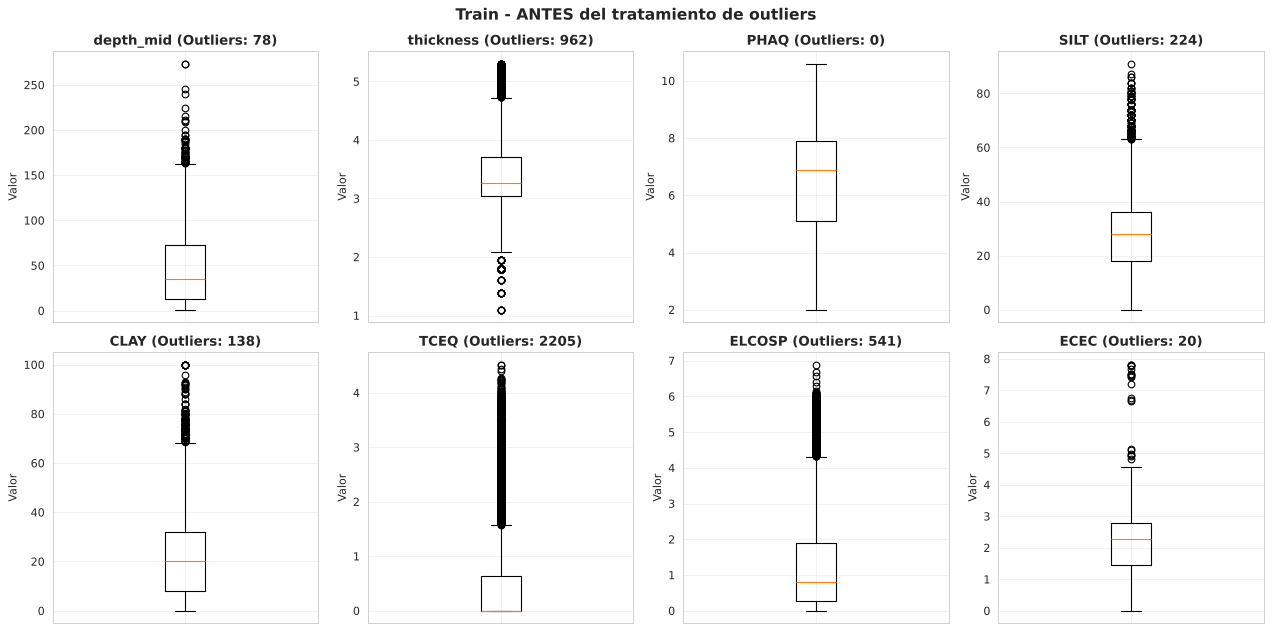

In [19]:
plot_boxplots(X_train, features_final, title='Train - ANTES del tratamiento de outliers')

#### 8.2 Decisión por feature

Se usa **clipping** (recortar al límite del IQR) en lugar de eliminar filas: conserva todas las capas, pero evita que los valores extremos dominen al modelo. Los límites se calculan **solo con train** y se aplican igual a test.

| Feature | Decisión | Justificación |
|---|---|---|
| `depth_mid`, `thickness`, `SILT`, `CLAY`, `ELCOSP`, `ECEC` | Clipping IQR | Pocos outliers después del log; los extremos (p. ej. `ECEC` = 2476 o `ELCOSP` = 980) son más probablemente errores de unidades que valores reales |
| `PHAQ` | Sin cambios | No presenta outliers tras eliminar los pH < 2 |
| `TCEQ` | **Sin clipping** | Más de la mitad de las capas tiene `TCEQ` = 0 (suelos no calcáreos), entonces Q1 = 0, el IQR es muy estrecho y se marcaría como outlier a buena parte de los **suelos calcáreos**. Son valores reales e informativos; el `log1p` ya acotó su escala (máx. ≈ 4.5) |

In [20]:
clip_cols = ['depth_mid', 'thickness', 'SILT', 'CLAY', 'ELCOSP', 'ECEC']

# Guardar límites calculados con train
clip_bounds = pd.DataFrame({
    'Límite inferior': lower_bound[clip_cols].round(3),
    'Límite superior': upper_bound[clip_cols].round(3)
})

# Decisión: transformar outliers con clipping (mismos límites para train y test)
for col in clip_cols:
    X_train[col] = X_train[col].clip(lower=lower_bound[col], upper=upper_bound[col])
    X_test[col] = X_test[col].clip(lower=lower_bound[col], upper=upper_bound[col])

clip_bounds

,Límite inferior,Límite superior
depth_mid,-77.500,162.500
thickness,2.041,4.717
SILT,-9.000,63.000
CLAY,-28.000,68.000
ELCOSP,-2.132,4.314
ECEC,-0.543,4.782


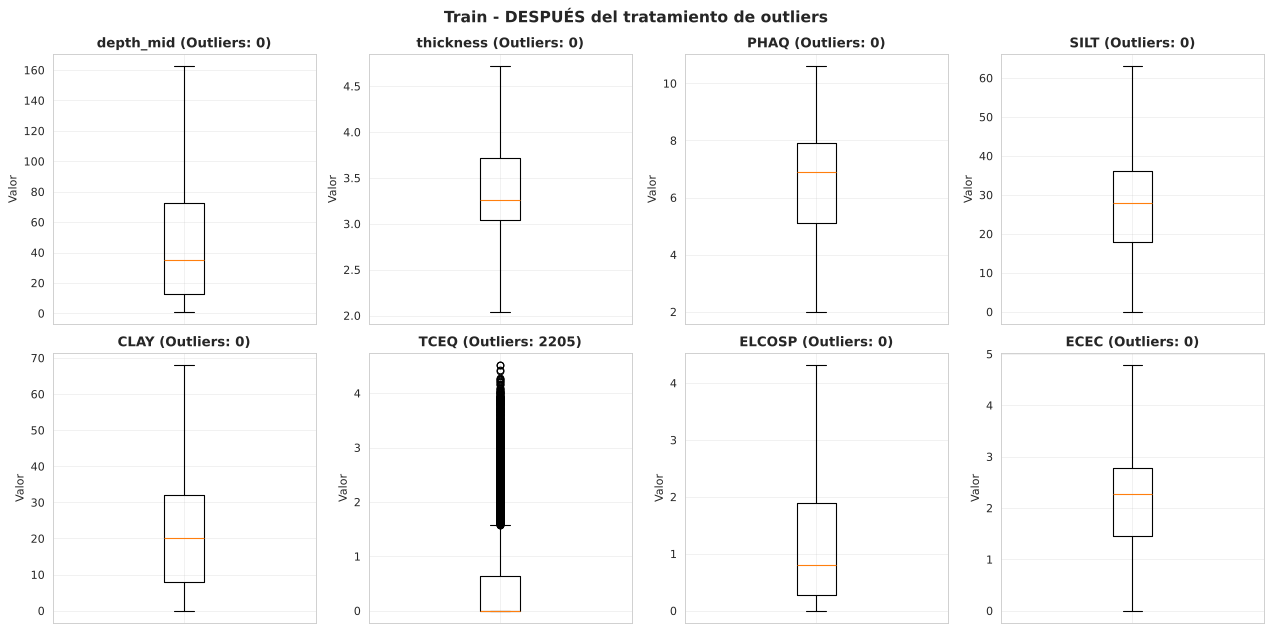

In [21]:
plot_boxplots(X_train, features_final, title='Train - DESPUÉS del tratamiento de outliers')

## 9. Tratamiento de datos faltantes

#### 9.1 Análisis de valores faltantes (train)

In [22]:
missing = X_train.isnull().sum()
missing_pct = (missing / len(X_train)) * 100

missing_df = pd.DataFrame({
    'Columna': missing.index,
    'Faltantes': missing.values,
    'Porcentaje (%)': missing_pct.values.round(2)
})

missing_df.sort_values('Faltantes', ascending=False)

,Columna,Faltantes,Porcentaje (%)
6,ELCOSP,6150,35.47
7,ECEC,4125,23.79
3,SILT,1602,9.24
4,CLAY,1585,9.14
5,TCEQ,1401,8.08
0,depth_mid,777,4.48
1,thickness,777,4.48
2,PHAQ,202,1.17


#### 9.2 Estrategia por feature

La imputación se hace **después** del log y del clipping, así la media/mediana se calcula sobre datos ya sin valores extremos.

Ninguna feature supera el 50 % de faltantes, por lo que todas se conservan. `ELCOSP` (~35 %) es la más afectada; se mantiene porque fue seleccionada en el EDA y eliminarla implicaría perder la información del 65 % de capas que sí la tienen.

No se eliminan filas con faltantes (`dropna`): perderíamos gran parte del dataset, ya que los faltantes de distintas columnas no coinciden en las mismas filas.

La regla para elegir el método de imputación es la **asimetría** (*skewness*) de cada feature:

- **|asimetría| < 0.5** (distribución aproximadamente simétrica, medida sobre los datos ya transformados) → **media**: representa bien el centro de los datos.
- **|asimetría| ≥ 0.5** (distribución sesgada o con outliers) → **mediana**: es resistente a valores extremos; la media quedaría "arrastrada" hacia la cola.

Se consideró KNN, pero con ~17 000 filas y features en escalas muy distintas (todavía sin escalar) su costo es mayor y sus distancias quedarían dominadas por las variables de mayor magnitud.

In [23]:
skewness = X_train.skew()

strategy_df = pd.DataFrame({
    'Columna': skewness.index,
    'Asimetría': skewness.values.round(2),
    'Faltantes (%)': missing_pct.values.round(2)
})
strategy_df['Estrategia'] = np.where(strategy_df['Asimetría'].abs() < 0.5, 'mean', 'median')

strategy_df

,Columna,Asimetría,Faltantes (%),Estrategia
0,depth_mid,0.92,4.48,median
1,thickness,0.38,4.48,mean
2,PHAQ,-0.27,1.17,mean
3,SILT,0.29,9.24,mean
4,CLAY,0.70,9.14,median
5,TCEQ,1.85,8.08,median
6,ELCOSP,1.10,35.47,median
7,ECEC,-0.66,23.79,median


In [24]:
cols_mean = strategy_df.loc[strategy_df['Estrategia'] == 'mean', 'Columna'].tolist()
cols_median = strategy_df.loc[strategy_df['Estrategia'] == 'median', 'Columna'].tolist()

print(f"Imputación por media: {cols_mean}")
print(f"Imputación por mediana: {cols_median}")

# Guardar copia antes de imputar (para comparar)
X_train_before_impute = X_train.copy()

# Ajustar SOLO con train y aplicar a train y test
imputer_mean = SimpleImputer(strategy='mean')
X_train[cols_mean] = imputer_mean.fit_transform(X_train[cols_mean])
X_test[cols_mean] = imputer_mean.transform(X_test[cols_mean])

imputer_median = SimpleImputer(strategy='median')
X_train[cols_median] = imputer_median.fit_transform(X_train[cols_median])
X_test[cols_median] = imputer_median.transform(X_test[cols_median])

Imputación por media: ['thickness', 'PHAQ', 'SILT']
Imputación por mediana: ['depth_mid', 'CLAY', 'TCEQ', 'ELCOSP', 'ECEC']


In [25]:
# Valores faltantes después de imputación
pd.DataFrame({
    'Train': X_train.isnull().sum(),
    'Test': X_test.isnull().sum()
})

,Train,Test
depth_mid,0,0
thickness,0,0
PHAQ,0,0
SILT,0,0
CLAY,0,0
TCEQ,0,0
ELCOSP,0,0
ECEC,0,0


Desv. estándar antes: 1.259 | después: 1.033


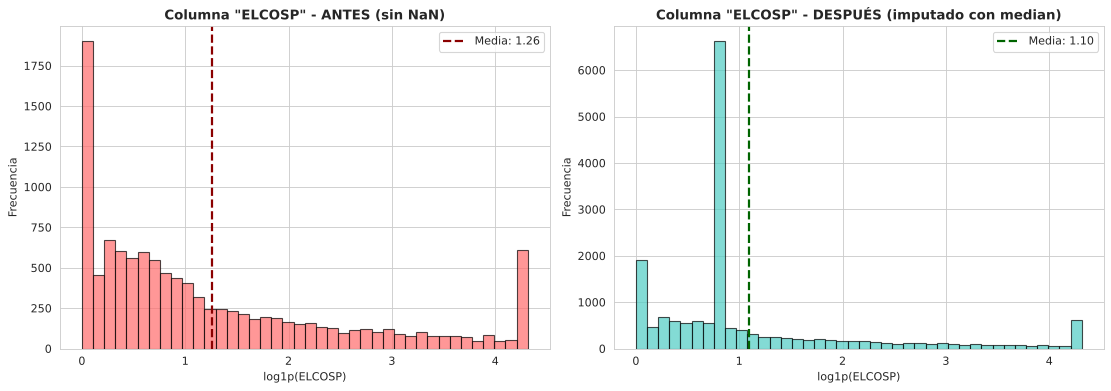

In [26]:
# Comparar antes y después de imputación en la feature con más faltantes
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

feature = 'ELCOSP'
metodo = strategy_df.set_index('Columna').loc[feature, 'Estrategia']
datos_antes = X_train_before_impute[feature].dropna()
datos_despues = X_train[feature]

for i, (datos, titulo, color) in enumerate([
    (datos_antes, 'ANTES (sin NaN)', '#FF6B6B'),
    (datos_despues, f'DESPUÉS (imputado con {metodo})', '#4ECDC4')
]):
    axes[i].hist(datos, bins=40, color=color, alpha=0.7, edgecolor='black')
    axes[i].axvline(datos.mean(), color='darkred' if i == 0 else 'darkgreen',
                    linestyle='--', linewidth=2, label=f'Media: {datos.mean():.2f}')
    axes[i].set_title(f'Columna "{feature}" - {titulo}', fontweight='bold')
    axes[i].set_xlabel('log1p(ELCOSP)')
    axes[i].set_ylabel('Frecuencia')
    axes[i].legend()

plt.tight_layout()
plt.show()

print(f"Desv. estándar antes: {datos_antes.std():.3f} | después: {datos_despues.std():.3f}")

Aparece un pico en el valor imputado, la media se acerca a la mediana y la desviación estándar disminuye. Es el costo esperado de imputar ~35 % de los datos con una constante (la varianza real queda subestimada); aun así es preferible a eliminar esas filas.

## 10. Transformación de la variable objetivo

`ORGC` sigue siendo muy asimétrica (la mayoría de capas tiene < 2 % y unas pocas, de suelos orgánicos, llegan a 50-100 %). Entrenar directamente sobre ella hace que los modelos (sobre todo los que minimizan el error cuadrático) se concentren en esos pocos valores altos.

Se crea `ORGC_log = log1p(ORGC)`. **Importante para la etapa de modelado:** las predicciones hechas sobre `ORGC_log` deben regresarse a % con `np.expm1()` antes de calcular las métricas finales. No se aplica clipping al target: los valores altos son reales y son justamente parte de lo que se quiere predecir.

In [27]:
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

target_df = pd.DataFrame({
    'Variable': ['ORGC', 'ORGC_log'],
    'Asimetría': [round(y_train.skew(), 2), round(y_train_log.skew(), 2)],
    'Media': [round(y_train.mean(), 3), round(y_train_log.mean(), 3)],
    'Mediana': [round(y_train.median(), 3), round(y_train_log.median(), 3)],
    'Máx': [round(y_train.max(), 3), round(y_train_log.max(), 3)]
})

target_df

,Variable,Asimetría,Media,Mediana,Máx
0,ORGC,7.33,2.005,0.690,98.780
1,ORGC_log,1.98,0.713,0.525,4.603


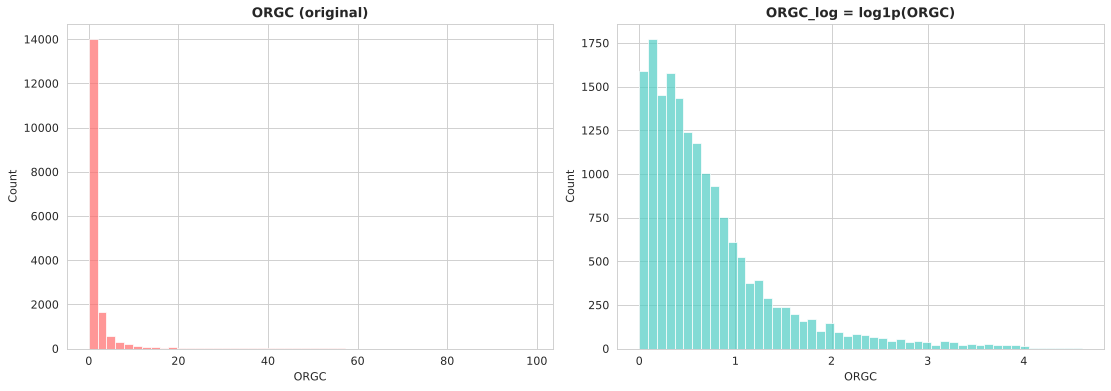

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(y_train, bins=50, ax=axes[0], color='#FF6B6B', alpha=0.7)
axes[0].set_title('ORGC (original)', fontweight='bold')

sns.histplot(y_train_log, bins=50, ax=axes[1], color='#4ECDC4', alpha=0.7)
axes[1].set_title('ORGC_log = log1p(ORGC)', fontweight='bold')

plt.tight_layout()
plt.show()

## 11. Escalamiento

Las features tienen rangos muy distintos (`depth_mid` llega a más de 150 cm, `TCEQ` en log no pasa de ~4.5). Para modelos sensibles a la escala (regresión lineal/Ridge/Lasso, KNN, SVR, redes neuronales) eso hace que las variables grandes dominen.

**¿Por qué `StandardScaler` y no `MinMaxScaler`?**

- Después del log y del clipping, las distribuciones están razonablemente centradas, que es el caso ideal para estandarizar (media 0, desviación 1).
- `MinMaxScaler` depende solo del mínimo y del máximo: en test pueden aparecer valores fuera del rango de train (p. ej. `TCEQ`, que no se recortó) y quedarían fuera de [0, 1].

Se guardan **dos versiones**: escalada (para modelos lineales y de distancias) y **sin escalar** (para modelos de árboles como Random Forest o XGBoost, que no lo necesitan y así se mantienen más interpretables).

In [29]:
# Crear copias para comparación
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_minmax = X_train.copy()

# StandardScaler: ajustar SOLO con train
scaler_standard = StandardScaler()
X_train_scaled[features_final] = scaler_standard.fit_transform(X_train[features_final])
X_test_scaled[features_final] = scaler_standard.transform(X_test[features_final])

# MinMax (solo para comparar)
scaler_minmax = MinMaxScaler()
X_train_minmax[features_final] = scaler_minmax.fit_transform(X_train[features_final])

print(f"Datos procesados: train {X_train_scaled.shape} | test {X_test_scaled.shape}")

Datos procesados: train (17338, 8) | test (4263, 8)


In [30]:
# Comparar estadísticas - Columna 'depth_mid'
col = 'depth_mid'

comparison_df = pd.DataFrame({
    'Método': ['Sin escalar', 'Standard', 'MinMax'],
    'Media': [X_train[col].mean(), X_train_scaled[col].mean(), X_train_minmax[col].mean()],
    'Desv. Estándar': [X_train[col].std(), X_train_scaled[col].std(), X_train_minmax[col].std()],
    'Mín': [X_train[col].min(), X_train_scaled[col].min(), X_train_minmax[col].min()],
    'Máx': [X_train[col].max(), X_train_scaled[col].max(), X_train_minmax[col].max()]
}).round(4)

comparison_df

,Método,Media,Desv. Estándar,Mín,Máx
0,Sin escalar,46.5798,38.8683,1.0000,162.5000
1,Standard,-0.0000,1.0000,-1.1727,2.9825
2,MinMax,0.2822,0.2407,0.0000,1.0000


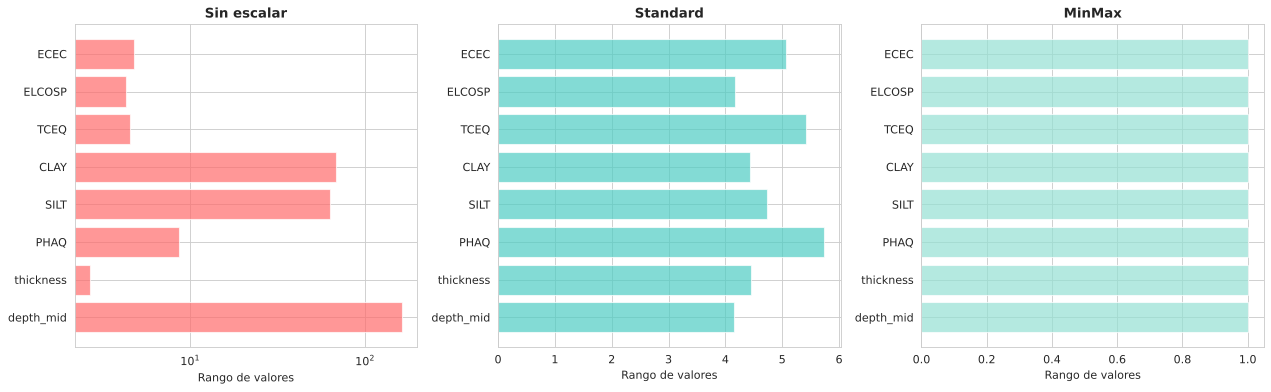

In [31]:
# Comparar escalas de todas las características
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
y_pos = np.arange(len(features_final))

datos = [
    (X_train, 'Sin escalar', '#FF6B6B', True),
    (X_train_scaled, 'Standard', '#4ECDC4', False),
    (X_train_minmax, 'MinMax', '#95E1D3', False)
]

for i, (df, title, color, log_scale) in enumerate(datos):
    ranges = [df[col].max() - df[col].min() for col in features_final]
    axes[i].barh(y_pos, ranges, color=color, alpha=0.7)
    axes[i].set_yticks(y_pos)
    axes[i].set_yticklabels(features_final)
    axes[i].set_xlabel('Rango de valores')
    axes[i].set_title(title, fontweight='bold')

    if log_scale:
        axes[i].set_xscale('log')

plt.tight_layout()
plt.show()

## 12. Balanceo de datos

**No aplica.** Técnicas como SMOTE o *class weights* sirven para problemas de **clasificación** con clases desbalanceadas. Aquí el target (`ORGC`) es continuo, por lo que no hay clases que balancear. La asimetría del target ya se trató con la transformación logarítmica (sección 10).

## 13. Verificación final y guardado

#### 13.1 Resumen de decisiones por feature

In [32]:
summary_df = pd.DataFrame({
    'Feature': features_final,
    'Origen': ['(upper + lower) / 2', 'lower - upper', 'original', 'original', 'original',
               'original', 'original', 'original'],
    'Imputación': [strategy_df.set_index('Columna').loc[c, 'Estrategia'] for c in features_final],
    'Log1p': ['sí' if c in log_cols else 'no' for c in features_final],
    'Clipping IQR': ['sí' if c in clip_cols else 'no' for c in features_final],
    'Escalado': ['StandardScaler'] * len(features_final)
})

summary_df

,Feature,Origen,Imputación,Log1p,Clipping IQR,Escalado
0,depth_mid,(upper + lower) / 2,median,no,sí,StandardScaler
1,thickness,lower - upper,mean,sí,sí,StandardScaler
2,PHAQ,original,mean,no,no,StandardScaler
3,SILT,original,mean,no,sí,StandardScaler
4,CLAY,original,median,no,sí,StandardScaler
5,TCEQ,original,median,sí,no,StandardScaler
6,ELCOSP,original,median,sí,sí,StandardScaler
7,ECEC,original,median,sí,sí,StandardScaler


In [33]:
check_df = pd.DataFrame({
    'Conjunto': ['X_train', 'X_test', 'X_train_scaled', 'X_test_scaled', 'y_train', 'y_test'],
    'Filas': [len(X_train), len(X_test), len(X_train_scaled), len(X_test_scaled), len(y_train), len(y_test)],
    'Columnas': [X_train.shape[1], X_test.shape[1], X_train_scaled.shape[1], X_test_scaled.shape[1], 1, 1],
    'NaN': [X_train.isnull().sum().sum(), X_test.isnull().sum().sum(),
            X_train_scaled.isnull().sum().sum(), X_test_scaled.isnull().sum().sum(),
            y_train.isnull().sum(), y_test.isnull().sum()]
})

check_df

,Conjunto,Filas,Columnas,NaN
0,X_train,17338,8,0
1,X_test,4263,8,0
2,X_train_scaled,17338,8,0
3,X_test_scaled,4263,8,0
4,y_train,17338,1,0
5,y_test,4263,1,0


#### 13.2 Guardar los datos procesados

Se guardan en `../data/processed/` para usarlos en el notebook de evaluación de modelos. Los archivos `y_*` contienen tanto `ORGC` (en %) como `ORGC_log`.

In [34]:
import os

output_dir = '../data/processed'
os.makedirs(output_dir, exist_ok=True)

# Features sin escalar (modelos de árboles)
X_train.to_csv(f'{output_dir}/X_train.csv', index=False)
X_test.to_csv(f'{output_dir}/X_test.csv', index=False)

# Features escaladas (modelos lineales, KNN, SVR, redes neuronales)
X_train_scaled.to_csv(f'{output_dir}/X_train_scaled.csv', index=False)
X_test_scaled.to_csv(f'{output_dir}/X_test_scaled.csv', index=False)

# Target original y transformado
pd.DataFrame({'ORGC': y_train.values, 'ORGC_log': y_train_log.values}).to_csv(f'{output_dir}/y_train.csv', index=False)
pd.DataFrame({'ORGC': y_test.values, 'ORGC_log': y_test_log.values}).to_csv(f'{output_dir}/y_test.csv', index=False)

print("Archivos guardados:")
for f in sorted(os.listdir(output_dir)):
    print(f" - {f}")

Archivos guardados:
 - X_test.csv
 - X_test_scaled.csv
 - X_train.csv
 - X_train_scaled.csv
 - y_test.csv
 - y_train.csv


## 14. Conclusiones

1. **Target:** se eliminaron las filas sin `ORGC` y con `ORGC` > 100 %; se generó `ORGC_log` para reducir la asimetría (recordar `np.expm1()` al evaluar).
2. **Consistencia:** las texturas que no suman 100 ± 5 y los pH < 2 se trataron como faltantes en lugar de eliminar filas completas.
3. **Redundancia:** `upper_depth`/`lower_depth` se reemplazaron por `depth_mid`/`thickness`, y se eliminó `SAND` (colinealidad perfecta con `SILT` + `CLAY`). Quedan **8 features**.
4. **Sin data leakage:** la división train/test se hizo **por perfil** y antes de cualquier paso que aprenda de los datos; imputadores, límites IQR y escalador se ajustaron solo con train.
5. **Outliers:** `log1p` en las variables con cola larga y clipping IQR calculado sobre valores reales, excepto en `TCEQ` (sus valores altos son reales).
6. **Faltantes:** imputados después de tratar outliers; media para features simétricas y mediana para las asimétricas.
7. **Escalado:** `StandardScaler`, guardando también la versión sin escalar.

**Para la evaluación de modelos:** usar `X_*_scaled` con modelos lineales, KNN, SVR o redes neuronales, y `X_*` (sin escalar) con modelos de árboles, entrenando sobre `ORGC_log`.